In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Una empresa estudia invertir en una nave logística con reparto de última milla (datos adjuntos; mismas hipótesis contables que en el caso base: amortización lineal hasta el valor residual, circulante como fracción de las ventas aportado al principio de cada año y recuperado al final, valor residual cobrado por su valor contable). Antes de decidir, la dirección quiere saber *cuánto pueden equivocarse* las previsiones sin que el proyecto deje de ser viable.

In [4]:
pregunta_1 = "1. Calcule los flujos de caja libre y el VAN del caso base.  "
pregunta_2 = "2. Umbrales de rentabilidad: ¿qué precio mínimo, qué volumen mínimo del año 1 y qué coste variable máximo hacen el VAN igual a cero (manteniendo lo demás)? Exprese cada uno como variación porcentual respecto al caso base. ¿A qué variable es más sensible el proyecto?  "
pregunta_3 = "3. Escenarios: pesimista (precio −10 %, unidades −10 %, costes fijos +10 %), base y optimista (precio +10 %, unidades +10 %, costes fijos −10 %). VAN y TIR de cada uno.  "
pregunta_4 = "4. Los datos están en euros constantes. Si se espera una inflación del 3% anual que afecta por igual a precios y costes, ¿cómo deben construirse los flujos en euros corrientes y qué tasa nominal hay que usar para que el VAN no cambie? Compruébelo (relación de Fisher).  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule los flujos de caja libre y el VAN del caso base.  

2. Umbrales de rentabilidad: ¿qué precio mínimo, qué volumen mínimo del año 1 y qué coste variable máximo hacen el VAN igual a cero (manteniendo lo demás)? Exprese cada uno como variación porcentual respecto al caso base. ¿A qué variable es más sensible el proyecto?  

3. Escenarios: pesimista (precio −10 %, unidades −10 %, costes fijos +10 %), base y optimista (precio +10 %, unidades +10 %, costes fijos −10 %). VAN y TIR de cada uno.  

4. Los datos están en euros constantes. Si se espera una inflación del 3% anual que afecta por igual a precios y costes, ¿cómo deben construirse los flujos en euros corrientes y qué tasa nominal hay que usar para que el VAN no cambie? Compruébelo (relación de Fisher).  

In [5]:
#| tbl-cap: "Datos del caso"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  parametro                                              , valor
    ('inversión inicial (k€)'                               , 1370 ),
    ('vida del proyecto (años)'                             , 5    ),
    ('precio (€ por miles de entrega)'                      , 4    ),
    ('miles de entregas vendidas el año 1'                  , 270  ),
    ('crecimiento anual de las unidades'                    , 0.03 ),
    ('coste variable unitario (€)'                          , 2    ),
    ('costes fijos anuales (k€)'                            , 115  ),
    ('valor residual al final (k€)'                         , 205  ),
    ('circulante necesario (fracción de las ventas del año)', 0.1  ),
    ('tipo impositivo'                                      , 0.25 ),
    ('tasa de descuento'                                    , 0.08 ),
], columns=['parametro', 'valor']).set_index('parametro')
datos_enunciado

,valor
parametro,
inversión inicial (k€),1370.00
vida del proyecto (años),5.00
precio (€ por miles de entrega),4.00
miles de entregas vendidas el año 1,270.00
crecimiento anual de las unidades,0.03
coste variable unitario (€),2.00
costes fijos anuales (k€),115.00
valor residual al final (k€),205.00
circulante necesario (fracción de las ventas del año),0.10


# Resolución

In [6]:
def van(flujos, k):
    '''Valor actual neto de una lista de flujos (el primero en t = 0) a la tasa k.'''
    return float(sum(f / (1 + k) ** t for t, f in enumerate(flujos)))

def tir(flujos):
    '''Tasa que anula el VAN (por bisección entre −99 % y 1000 %).'''
    from scipy.optimize import brentq
    return float(brentq(lambda k: van(flujos, k), -0.99, 10.0))

def tabla_descuento(flujos, k):
    '''Año, flujo, factor de descuento, valor actual y valores acumulados (simple y descontado).'''
    t = pd.DataFrame({'flujo': list(flujos)}, index=pd.Index(range(len(flujos)), name='año'))
    t['(1 + k)^-t'] = [(1 + k) ** -i for i in t.index]
    t['valor actual'] = t['flujo'] * t['(1 + k)^-t']
    t['acumulado'] = t['flujo'].cumsum()
    t['acumulado descontado'] = t['valor actual'].cumsum()
    return t

def payback(flujos, k=None):
    '''Periodo de recuperación (años, con interpolación lineal dentro del año); descontado si se da k.'''
    acum = 0.0
    for t, f in enumerate(flujos):
        v = f if k is None else f / (1 + k) ** t
        if t > 0 and acum < 0 <= acum + v:
            return float(t - 1 + (-acum) / v)
        acum += v
    return float('inf')

def anualidad_equivalente(VAN, k, n):
    '''Anualidad constante durante n años cuyo valor actual es VAN.'''
    return float(VAN * k / (1 - (1 + k) ** -n))

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Calcule los flujos de caja libre y el VAN del caso base.  

In [8]:
p = datos_enunciado['valor'].to_dict()
I0, n, precio = p['inversión inicial (k€)'], int(p['vida del proyecto (años)']), [v for c, v in p.items() if c.startswith('precio')][0]
u1 = [v for c, v in p.items() if 'año 1' in c][0]
g, cv, CF = p['crecimiento anual de las unidades'], p['coste variable unitario (€)'], p['costes fijos anuales (k€)']
VR, w, t_imp, k = p['valor residual al final (k€)'], p['circulante necesario (fracción de las ventas del año)'], p['tipo impositivo'], p['tasa de descuento']

In [9]:
#| tbl-cap: "Flujos de caja libre del proyecto (k€)"
#| label: tbl-flujos
anos = list(range(0, n + 1))
unidades = pd.Series([0] + [u1 * (1 + g) ** (t - 1) for t in range(1, n + 1)], index=anos)
ventas = unidades * precio
costes_variables = unidades * cv
costes_fijos = pd.Series([0] + [CF] * n, index=anos)
EBITDA = ventas - costes_variables - costes_fijos
amortizacion = pd.Series([0] + [(I0 - VR) / n] * n, index=anos)
BAI = EBITDA - amortizacion
impuesto = BAI.clip(lower=0) * t_imp; impuesto[0] = 0
BDI = BAI - impuesto
circulante = pd.Series([w * ventas[1]] + [w * ventas[t] for t in range(1, n + 1)], index=anos)   # el del año 1 se aporta en t = 0
variacion_circulante = circulante.diff().fillna(circulante[0]); variacion_circulante[n] -= circulante[n]   # se recupera al final
inversion = pd.Series([I0] + [0] * n, index=anos)
valor_residual = pd.Series([0] * n + [VR], index=anos)
FCL = BDI + amortizacion - variacion_circulante - inversion + valor_residual
tabla = pd.DataFrame({'unidades': unidades, 'ventas': ventas, 'costes variables': costes_variables, 'costes fijos': costes_fijos,
                      'EBITDA': EBITDA, 'amortización': amortizacion, 'BAI': BAI, 'impuesto': impuesto, 'BDI': BDI,
                      '+ amortización': amortizacion, '− Δ circulante': -variacion_circulante, '− inversión': -inversion,
                      '+ valor residual': valor_residual, 'FCL': FCL})
tabla.index.name = 'año'
flujos = FCL.tolist()
tabla.round(1).T

año,0,1,2,3,4,5
unidades,0.0,270.0,278.1,286.4,295.0,303.9
ventas,0.0,1080.0,1112.4,1145.8,1180.1,1215.5
costes variables,0.0,540.0,556.2,572.9,590.1,607.8
costes fijos,0.0,115.0,115.0,115.0,115.0,115.0
EBITDA,0.0,425.0,441.2,457.9,475.1,492.8
amortización,0.0,233.0,233.0,233.0,233.0,233.0
BAI,0.0,192.0,208.2,224.9,242.1,259.8
impuesto,0.0,48.0,52.1,56.2,60.5,64.9
BDI,0.0,144.0,156.2,168.7,181.6,194.8
+ amortización,0.0,233.0,233.0,233.0,233.0,233.0


In [10]:
def modelo(precio=precio, u1=u1, cv=cv, CF=CF, g=g, I0=I0, n=n, VR=VR, w=w, t_imp=t_imp, inflacion=0.0):
    '''Flujos de caja libre del modelo; con inflación, en euros corrientes (precios y costes crecen cada año).'''
    unidades = pd.Series([0] + [u1 * (1 + g) ** (t - 1) for t in range(1, n + 1)])
    infl = pd.Series([(1 + inflacion) ** t for t in range(n + 1)])
    ventas = unidades * precio * infl; EBITDA = ventas - unidades * cv * infl - pd.Series([0] + [CF] * n) * infl
    amort = pd.Series([0] + [(I0 - VR) / n] * n); BAI = EBITDA - amort
    imp = BAI.clip(lower=0) * t_imp; imp[0] = 0
    circ = pd.Series([w * ventas[1]] + [w * ventas[t] for t in range(1, n + 1)])
    dcirc = circ.diff().fillna(circ[0]); dcirc[n] -= circ[n]
    return (BAI - imp + amort - dcirc - pd.Series([I0] + [0] * n) + pd.Series([0] * n + [VR])).tolist()
VAN = van(modelo(), k)
Markdown(f'VAN del caso base: {VAN:.1f} k€ (TIR {tir(modelo()):.2%}).')

VAN del caso base: 331.3 k€ (TIR 15.31%).

## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. Umbrales de rentabilidad: ¿qué precio mínimo, qué volumen mínimo del año 1 y qué coste variable máximo hacen el VAN igual a cero (manteniendo lo demás)? Exprese cada uno como variación porcentual respecto al caso base. ¿A qué variable es más sensible el proyecto?  

Cada umbral se obtiene resolviendo VAN(x) = 0 en la variable x (bisección), con las demás fijas. La sensibilidad se lee en la variación porcentual que anula el VAN: cuanto menor, más frágil es el proyecto frente a esa variable.

In [12]:
from scipy.optimize import brentq
precio_umbral = brentq(lambda x: van(modelo(precio=x), k), precio * 0.2, precio * 2)
u1_umbral = brentq(lambda x: van(modelo(u1=x), k), u1 * 0.2, u1 * 2)
cv_umbral = brentq(lambda x: van(modelo(cv=x), k), cv * 0.2, max(cv * 5, precio * 0.99))
umbrales = pd.DataFrame({'caso base': [precio, u1, cv], 'umbral (VAN = 0)': [precio_umbral, u1_umbral, cv_umbral]},
                        index=['precio', 'unidades año 1', 'coste variable'])
umbrales['variación admisible'] = umbrales['umbral (VAN = 0)'] / umbrales['caso base'] - 1
display(umbrales.round(3))
mas_sensible = umbrales['variación admisible'].abs().idxmin()
Markdown(f'La variable más sensible es **{mas_sensible}**: basta una variación del {umbrales.loc[mas_sensible, "variación admisible"]:+.1%} para anular el VAN.')

,caso base,umbral (VAN = 0),variación admisible
precio,4.0,3.608,-0.098
unidades año 1,270.0,216.547,-0.198
coste variable,2.0,2.388,0.194


La variable más sensible es **precio**: basta una variación del -9.8% para anular el VAN.

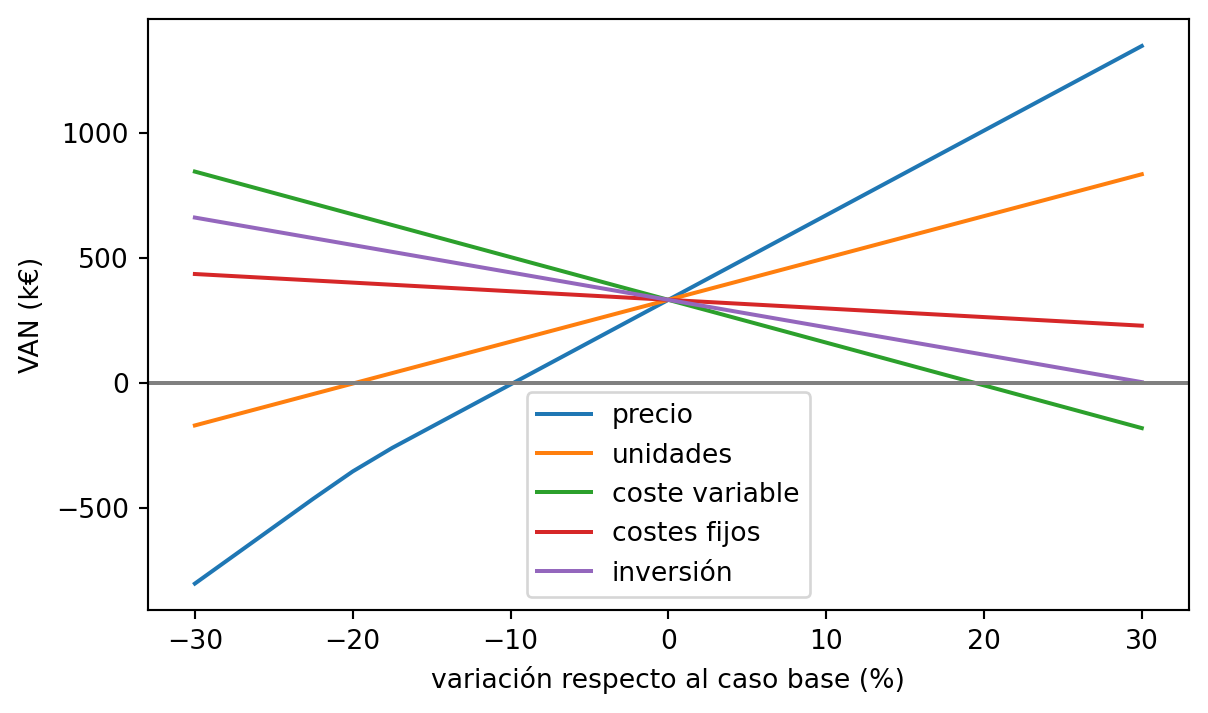

In [13]:
#| fig-cap: "VAN frente a la variación de cada variable (diagrama de araña)"
#| label: fig-arana
from matplotlib import pyplot as plt
xs = np.linspace(-0.3, 0.3, 25)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(xs * 100, [van(modelo(precio=precio * (1 + x)), k) for x in xs], label='precio')
ax.plot(xs * 100, [van(modelo(u1=u1 * (1 + x)), k) for x in xs], label='unidades')
ax.plot(xs * 100, [van(modelo(cv=cv * (1 + x)), k) for x in xs], label='coste variable')
ax.plot(xs * 100, [van(modelo(CF=CF * (1 + x)), k) for x in xs], label='costes fijos')
ax.plot(xs * 100, [van(modelo(I0=I0 * (1 + x)), k) for x in xs], label='inversión')
ax.axhline(0, color='grey'); ax.set_xlabel('variación respecto al caso base (%)'); ax.set_ylabel('VAN (k€)'); ax.legend(); plt.show()

## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. Escenarios: pesimista (precio −10 %, unidades −10 %, costes fijos +10 %), base y optimista (precio +10 %, unidades +10 %, costes fijos −10 %). VAN y TIR de cada uno.  

In [15]:
escenarios = {'pesimista': dict(precio=precio * 0.9, u1=u1 * 0.9, CF=CF * 1.1), 'base': {}, 'optimista': dict(precio=precio * 1.1, u1=u1 * 1.1, CF=CF * 0.9)}
tabla_esc = pd.DataFrame({e: {'VAN (k€)': van(modelo(**kw), k), 'TIR': tir(modelo(**kw))} for e, kw in escenarios.items()}).T
display(tabla_esc.round(3))
Markdown(f'''El escenario pesimista {"mantiene" if tabla_esc.loc["pesimista", "VAN (k€)"] > 0 else "destruye"} la viabilidad (VAN {tabla_esc.loc["pesimista", "VAN (k€)"]:.1f}). Los escenarios combinan desviaciones simultáneas, que es lo que ocurre en la práctica (un mal año afecta a precio y volumen a la vez); el análisis de una variable cada vez las subestima.''')

,VAN (k€),TIR
pesimista,-174.923,0.039
base,331.331,0.153
optimista,905.242,0.268


El escenario pesimista destruye la viabilidad (VAN -174.9). Los escenarios combinan desviaciones simultáneas, que es lo que ocurre en la práctica (un mal año afecta a precio y volumen a la vez); el análisis de una variable cada vez las subestima.

## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. Los datos están en euros constantes. Si se espera una inflación del 3% anual que afecta por igual a precios y costes, ¿cómo deben construirse los flujos en euros corrientes y qué tasa nominal hay que usar para que el VAN no cambie? Compruébelo (relación de Fisher).  

In [17]:
inflacion = 0.03
k_nominal = (1 + k) * (1 + inflacion) - 1
flujos_corrientes = modelo(inflacion=inflacion)
VAN_corriente = van(flujos_corrientes, k_nominal)
VAN_corriente_mal = van(flujos_corrientes, k)
display(pd.DataFrame({'euros constantes': modelo(), 'euros corrientes': flujos_corrientes}, index=pd.Index(range(n + 1), name='año')).T.round(1))
Markdown(f'''Relación de Fisher: (1 + k_nominal) = (1 + k_real)(1 + π) → k_nominal = (1 + {k})(1 + {inflacion}) − 1 = {k_nominal:.2%}. Flujos corrientes descontados a la tasa nominal: VAN = {VAN_corriente:.1f} k€, frente a {VAN:.1f} con flujos constantes y tasa real. No coinciden porque no todo crece con la inflación: la amortización (y su ahorro fiscal) y el valor residual son importes nominales fijos, y el circulante crece con las ventas nominales; la inflación perjudica al proyecto vía impuestos y circulante. El error grave sería mezclar: flujos corrientes con tasa real daría {VAN_corriente_mal:.1f} k€, un VAN inflado.''')

año,0,1,2,3,4,5
euros constantes,-1478.0,377.0,385.9,398.3,411.1,750.8
euros corrientes,-1481.2,386.6,402.5,426.3,451.6,824.5


Relación de Fisher: (1 + k_nominal) = (1 + k_real)(1 + π) → k_nominal = (1 + 0.08)(1 + 0.03) − 1 = 11.24%. Flujos corrientes descontados a la tasa nominal: VAN = 280.3 k€, frente a 331.3 con flujos constantes y tasa real. No coinciden porque no todo crece con la inflación: la amortización (y su ahorro fiscal) y el valor residual son importes nominales fijos, y el circulante crece con las ventas nominales; la inflación perjudica al proyecto vía impuestos y circulante. El error grave sería mezclar: flujos corrientes con tasa real daría 453.3 k€, un VAN inflado.